Analyze time-series data from platereader experiments.

## Setup 

In [1]:
%load_ext autoreload
%autoreload 2
    
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from cdk import logging
log = logging.setup_logging(logging.ERROR)

# Import the cdk platereader module
from cdk.instruments import platereader as pr

## Load Data

In [2]:
# Specify file paths
data_file = "sample-data/20251111-122213-cytation5-pure-timecourse-gfp-MFG-98-tRNA-QC.txt"
platemap_file = "sample-data/platemap.csv"

# Load data
result = pr.load_platereader_data(
    data_file=data_file,
    platemap_file=platemap_file,
    platereader="biotek" # options: "biotek"
)

[06/25/26 23:54:04] INFO     Found 1 plate blocks                  biotek.py:105
                    INFO     Parsing plate block 1                 biotek.py:112
                    INFO     Read metadata section, found 2 read   biotek.py:213
                             block(s).                                          
                    INFO     Parsed 2 segment(s) successfully.     biotek.py:466
                    INFO     Found 0 segment(s) that could not be  biotek.py:467
                             associated with existing read data.                
                    WARNING  Platemap 'Type' column contains     platemap.py:141
                             unexpected values: ['Rxn Control'].                
                             Expected one of: ['Blank',                         
                             'Negative Control', 'Positive                      
                             Control', 'Sample', 'Standard'].                   


The output is a list of `PlateReaderResult` objects; if you did more than one read on the plate reader, the results will be in separate objects.

In [3]:
print(result)

PlateReaderResult with the following 2 blocks:
0: (1533, 54) kinetic read with reads: GFP-G70:485,528 (Fluorescence) (Plate 'Plate 1')
1: (1533, 54) kinetic read with reads: GFP-Gext:485,528 (Fluorescence) (Plate 'Plate 1')


Here there were two reads with different gains but the same excitation/emission spectrum, on one plate. If we want just the `GFP-Gext` read, this corresponds to block index 1, so we can extract that block by indexing:

In [4]:
desired_index = 1
data = result[desired_index]
data

(1533, 54) kinetic read with reads: GFP-Gext:485,528 (Fluorescence)

## Plot Raw Curves

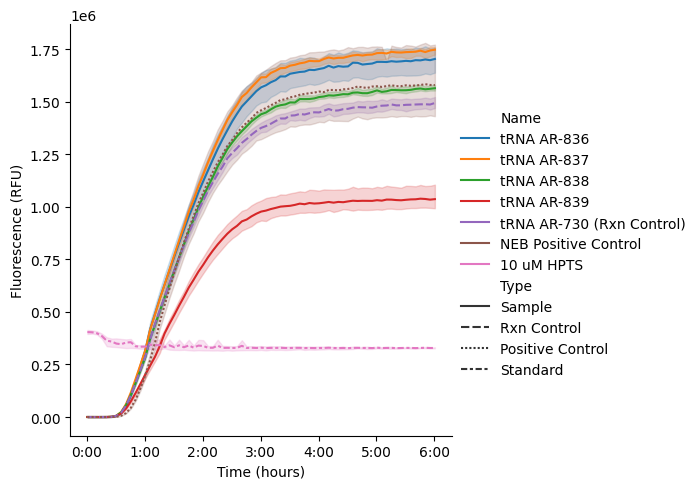

In [5]:
data.plot(style='Type')

We can see that the standard (here, HPTS) is stable and can be safely used for normalization. 

## Normalize Data
Now, use `data.normalize('<standard name>')` to normalize your data. This will calculate the average over a time window at the end of the experiment (by default, 1 hour), then divide all data by the mean of that window-average across all wells with the same `Name` (defined by your platemap).

In [6]:
# To check the exact name of your standard
data[data['Type'] == 'Standard'].Name.unique()

array(['10 uM HPTS'], dtype=object)

In [7]:
data = data.normalize('10 uM HPTS')

Now replot your curves to see them normalized:

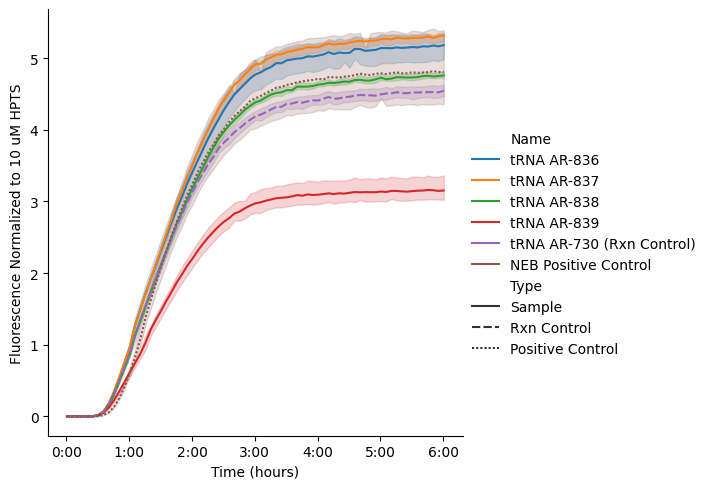

In [8]:
g = data.plot(style='Type', exclude_types=['Standard'])
# g.savefig('after-normalization.png',dpi=300)

If you want to change the time window over which you calculate the average, you can use the `window` argument:

In [9]:
# data = data.normalize('10 uM HPTS', window=pd.Timedelta("2.5h"))

## Kinetic Analysis

See the [DevNote](https://devnotes.nucleus.engineering/articles/Newman-20260421) on kinetic analysis for more details.

**Metrics extracted:**

  - **Maximum velocity**: Maximum rate of fluorescence increase (slope at inflection point)
  - **Lag time**: Time to reach the exponential phase
  - **Steady-state**: Final fluorescence level
  - **Time-to-completion**: Time it takes to reach 95% of asymptote
  - **Drift**: Rate of signal decay or increase after steady-state
  - **R²**: Goodness of fit; "Good Fit" is `True` if $R^2 \geq 0.95$

In [10]:
# Perform kinetic analysis using sigmoid_drift model
kinetics = data.fit_kinetics()

[06/25/26 23:54:13] INFO     Calculating Kinetics                analysis.py:223


In [11]:
kinetics.summary

,Well,Name,Max Velocity,Max Velocity Time,Lag Time,Steady State,Completion Time,Completion Threshold,Drift,Fit Function,R^2,Good Fit,Normalized to
0,B2,tRNA AR-836,2.49,0 days 01:33:15,0 days 00:33:09,4.74,0 days 03:01:44,0.95,0.07,sigmoid_drift,1.00,True,10 uM HPTS
1,B4,tRNA AR-837,2.67,0 days 01:33:35,0 days 00:34:38,4.99,0 days 03:00:24,0.95,0.07,sigmoid_drift,1.00,True,10 uM HPTS
2,B6,tRNA AR-838,2.44,0 days 01:32:35,0 days 00:34:21,4.50,0 days 02:58:17,0.95,0.06,sigmoid_drift,1.00,True,10 uM HPTS
3,B8,tRNA AR-839,1.68,0 days 01:32:00,0 days 00:37:35,2.89,0 days 02:52:07,0.95,0.03,sigmoid_drift,1.00,True,10 uM HPTS
4,B10,tRNA AR-730 (Rxn Control),2.37,0 days 01:30:01,0 days 00:33:50,4.22,0 days 02:52:45,0.95,0.07,sigmoid_drift,1.00,True,10 uM HPTS
5,B12,NEB Positive Control,2.66,0 days 01:35:50,0 days 00:45:09,4.27,0 days 02:50:26,0.95,0.09,sigmoid_drift,1.00,True,10 uM HPTS
6,D2,tRNA AR-836,2.64,0 days 01:31:44,0 days 00:32:12,4.97,0 days 02:59:23,0.95,0.08,sigmoid_drift,1.00,True,10 uM HPTS
7,D4,tRNA AR-837,2.79,0 days 01:32:13,0 days 00:34:27,5.10,0 days 02:57:16,0.95,0.07,sigmoid_drift,1.00,True,10 uM HPTS
8,D6,tRNA AR-838,2.52,0 days 01:32:00,0 days 00:34:31,4.58,0 days 02:56:37,0.95,0.06,sigmoid_drift,1.00,True,10 uM HPTS
9,D8,tRNA AR-839,1.84,0 days 01:30:32,0 days 00:35:41,3.20,0 days 02:51:17,0.95,0.04,sigmoid_drift,1.00,True,10 uM HPTS


## Visualize Fits

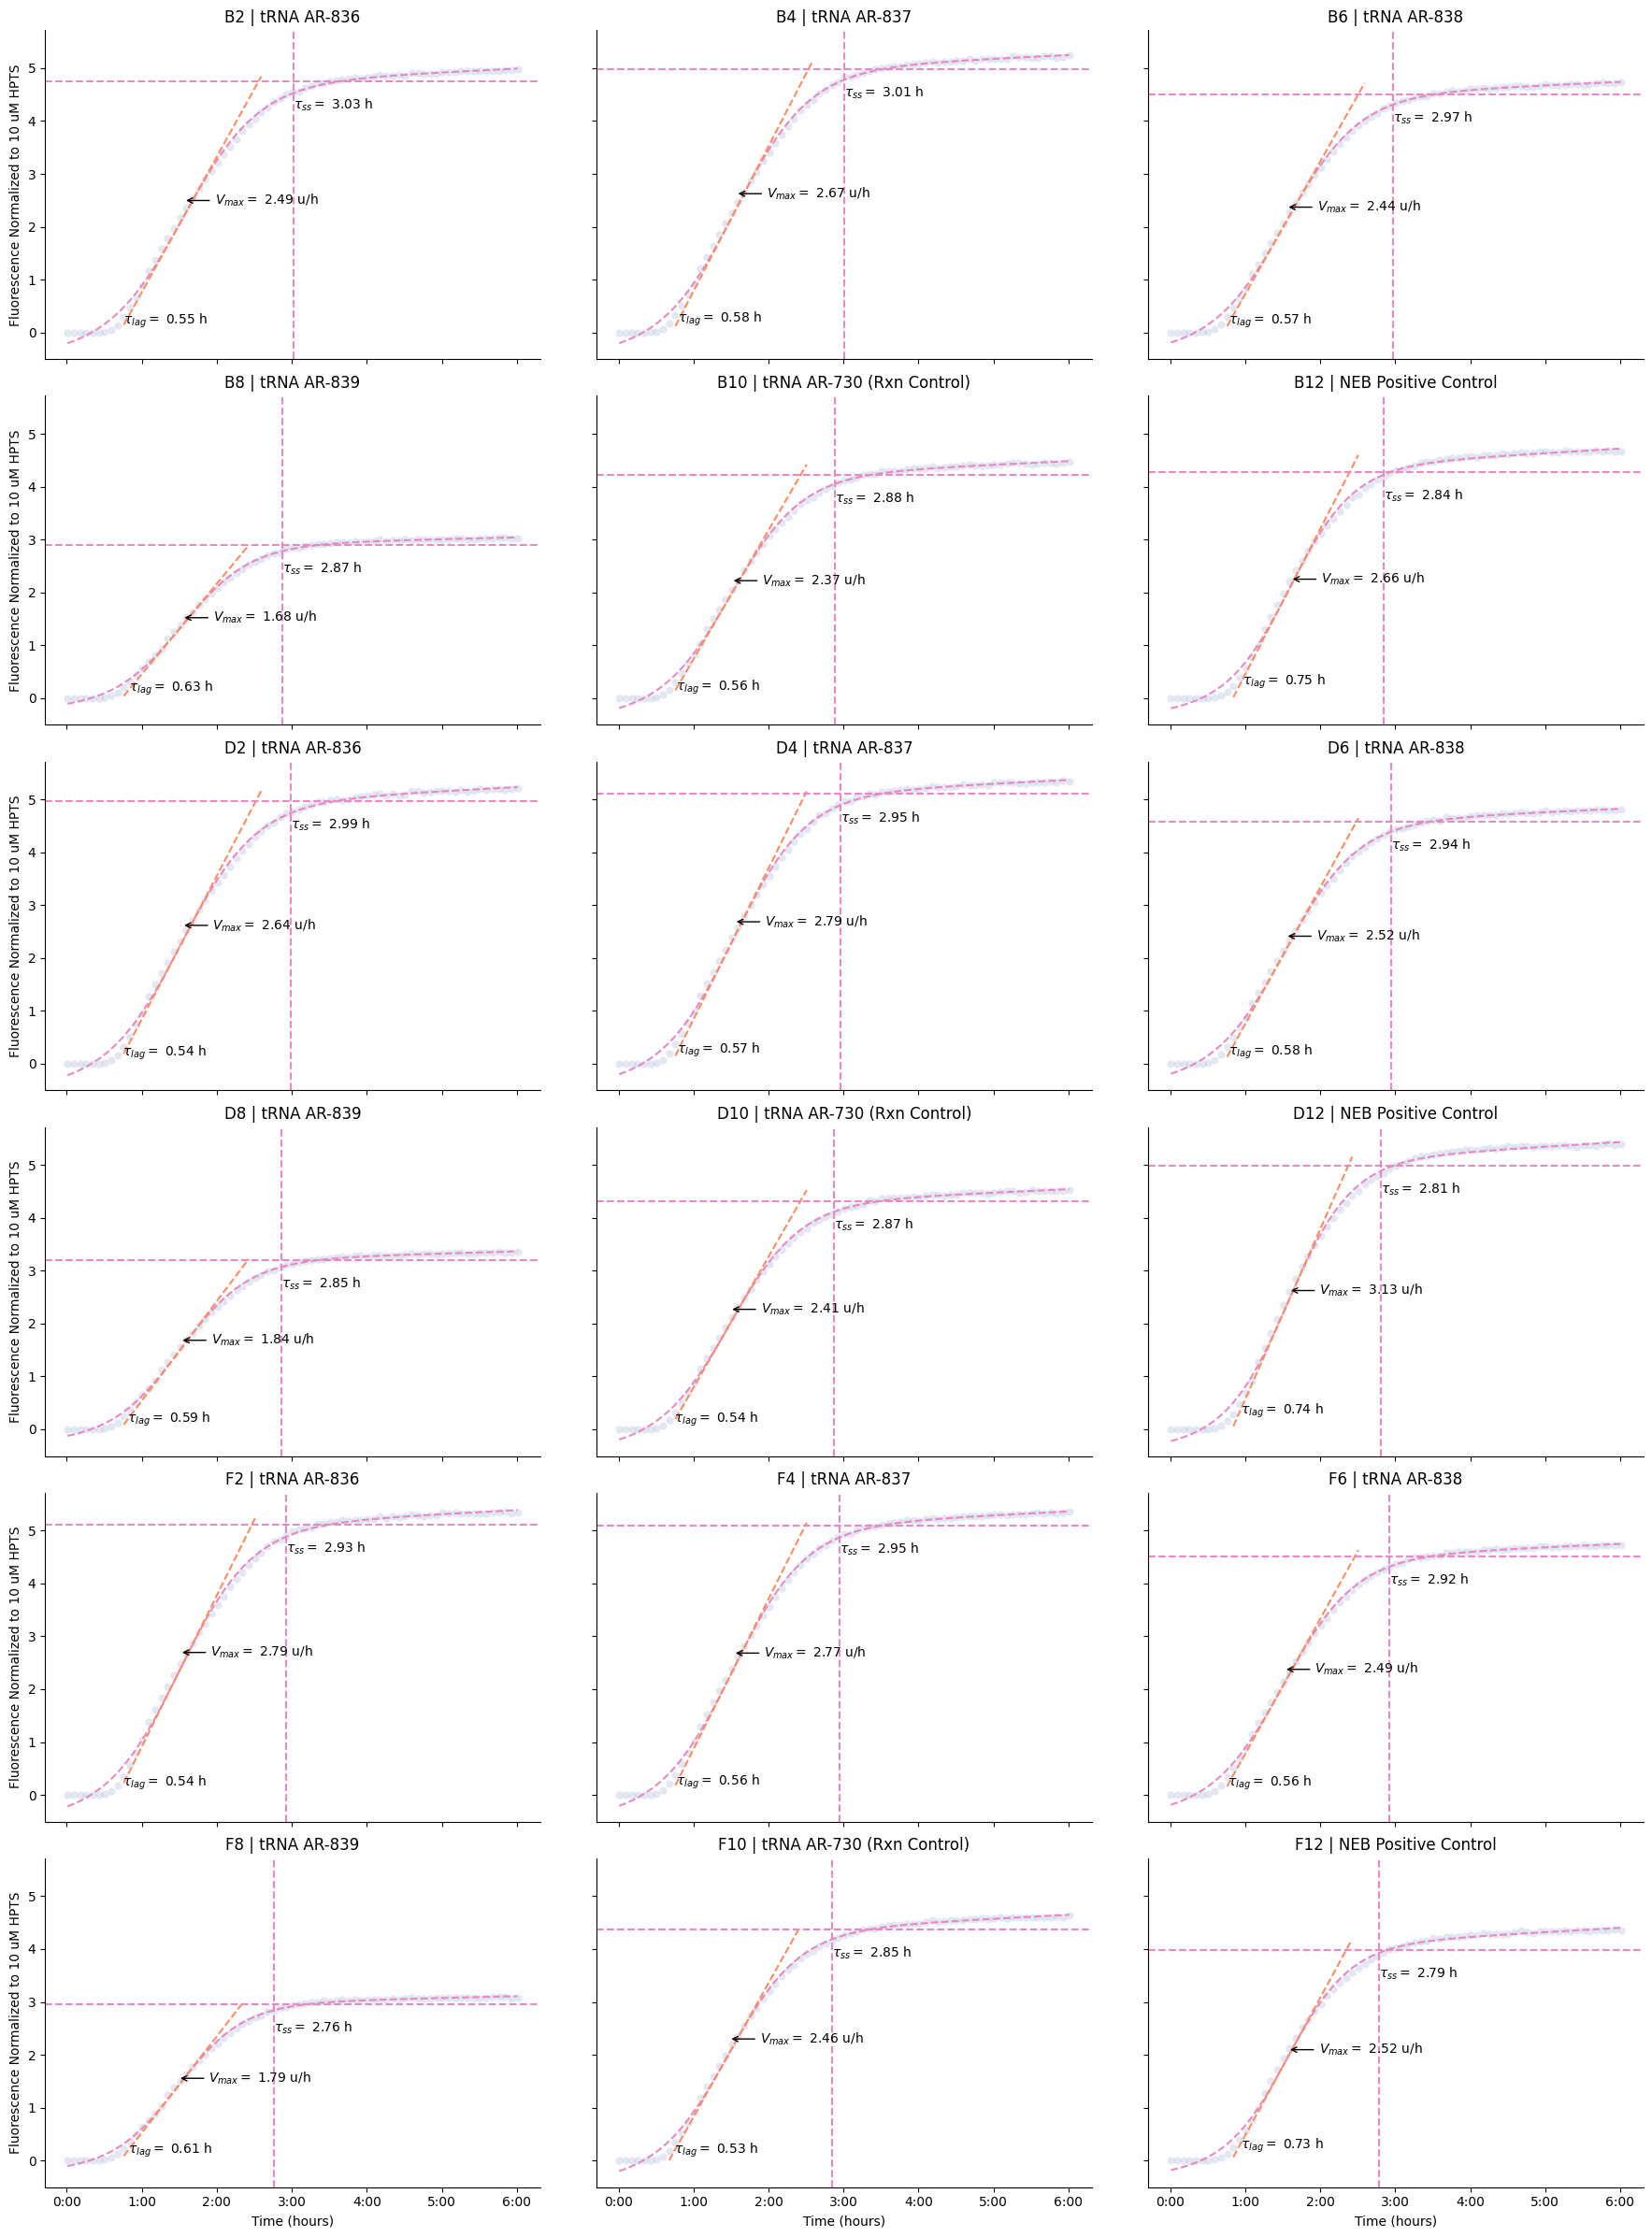

In [12]:
g = kinetics.plot(col="Well")
# g = kinetics.plot() # call this to visualize across replicates

## Summary Plots

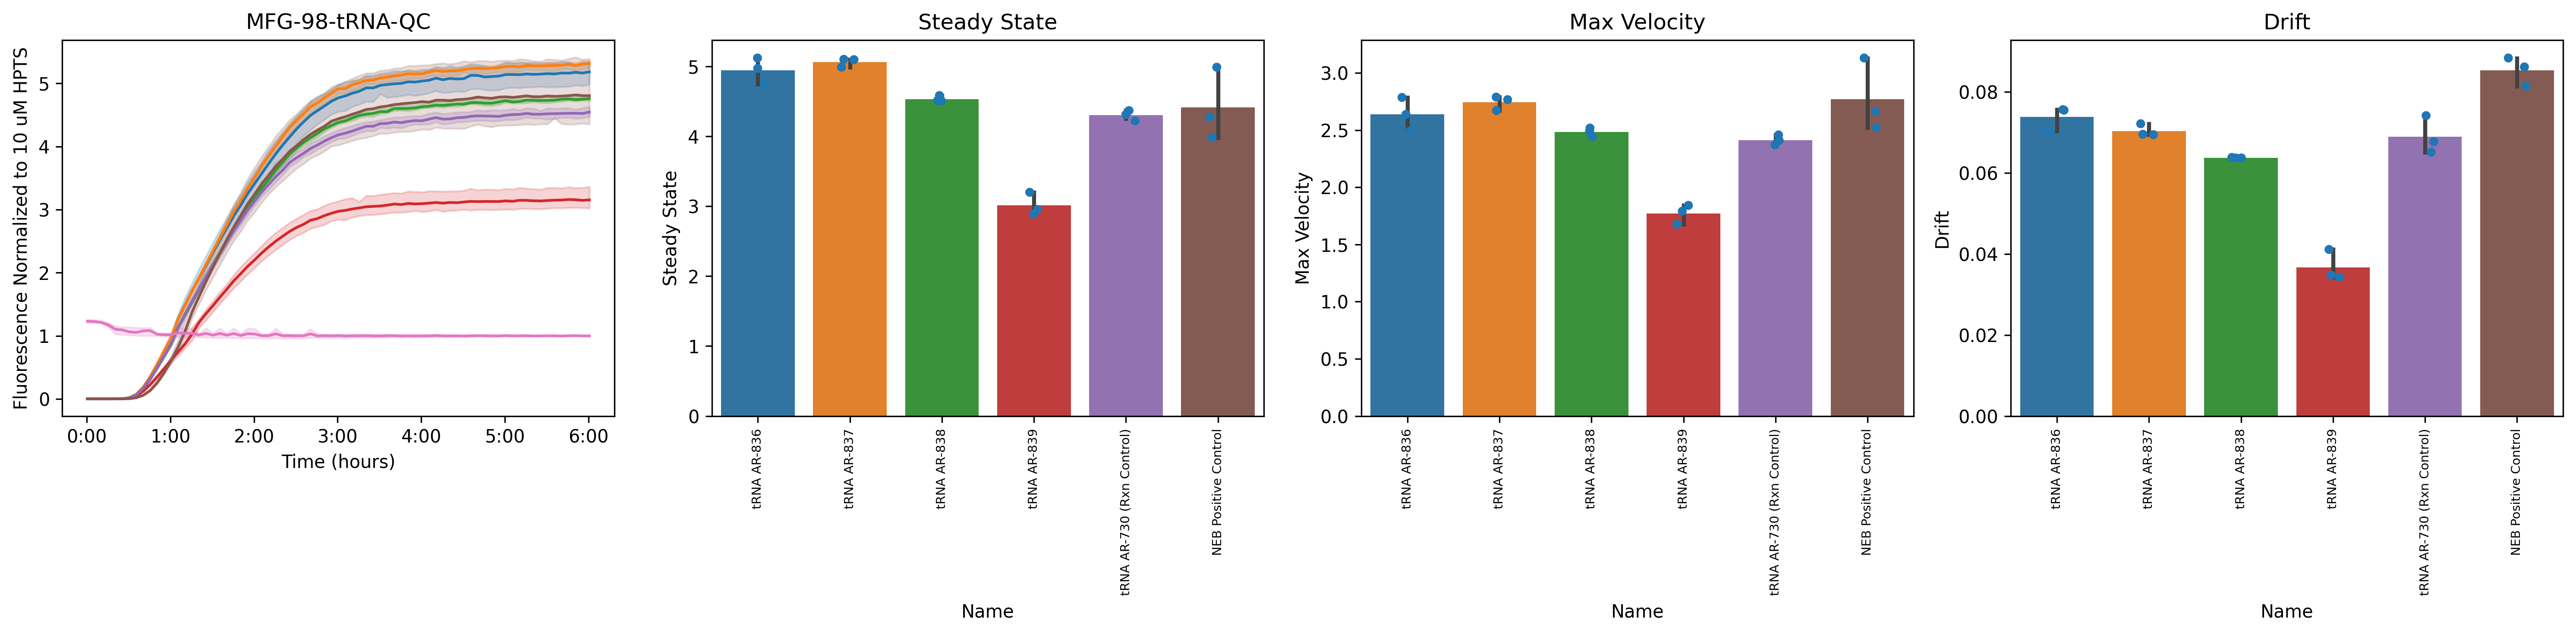

In [13]:
g = kinetics.plot_summary()

---

## Key Metrics Explained

### 1. **Steady-State Level** (`Steady State, Data`)
- The final fluorescence value reached by the reaction
- Represents the total amount of protein produced
- Higher values indicate greater expression yield

### 2. **Maximum Velocity** (`Velocity, Max`)
- The steepest slope of the fluorescence curve (at the inflection point)
- Units: RFU per second
- Reflects the peak rate of protein synthesis
- Sensitive to enzyme activity, substrate availability, and reaction conditions

### 3. **Lag Time** (`Lag, Time`)
- Time before exponential fluorescence increase begins
- May reflect time for ribosome assembly or initial translation steps
- Shorter lag times suggest faster reaction initiation

### 4. **Drift** (`Fit, drift`)
- Rate of fluorescence change after reaching steady-state
- Positive drift: continued synthesis or aggregation
- Negative drift: photobleaching, protein degradation, or quenching
- Units: RFU per second

### 5. **R² Value** (`Fit, R^2`)
- Goodness of fit (0 to 1, higher is better)
- R² > 0.98 indicates excellent fit
- Poor fits may indicate noisy data, overflow errors, or non-sigmoid kinetics

---

## Tips and Troubleshooting

- **Overflow errors:** Wells with `OVRFLW` or `NaN` values are automatically excluded from fitting
- **Poor fits (low R²):** Inspect raw curves for anomalies (bubbles, evaporation, pipetting errors)
- **Drift:** Sometimes seen in kinetics curves; use `sigmoid_drift` model
- **Multiple replicates:** Always include technical replicates and report error bars
- **Comparing conditions:** Normalize or blank data consistently across all samples

---

## Next Steps

- Export kinetics results: `pr.export_kinetics(kinetics, 'results.csv')`
- Statistical analysis: Use `scipy.stats` or `statsmodels` for ANOVA/t-tests
- Parameter optimization: Vary Mg²⁺, K⁺, or other conditions to maximize Vmax or steady-state
- Mechanistic modeling: Fit ODE models to extract biological rate constants